# 2.1.4 BÀI TẬP THỰC HÀNH 2: DỰ ĐOÁN BỆNH TIỂU ĐƯỜNG PIMA INDIANS
Mô hình: Decision Tree và Random Forest
Thực hiện: Lê Văn Hiếu


### 1. Khám phá và tiền xử lý dữ liệu: Xử lý giá trị 0 sinh lý bất thường


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)

di_path = '../data/diabetes.csv' if os.path.exists('../data/diabetes.csv') else 'Lab05_ThucHanhBaiToanPhanLop/data/diabetes.csv'
df = pd.read_csv(di_path)

print("Kich thuoc tap du lieu goc:", df.shape)
print("Phan bo nhan Outcome:\n", df['Outcome'].value_counts())

cols_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X_raw = df[features]
y = df['Outcome']

# Chia train/test truoc de tranh Data Leakage
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

for col in cols_zero:
    X_train[col] = X_train[col].replace(0, np.nan)
    med = X_train[col].median()
    X_train[col] = X_train[col].fillna(med)
    X_test[col] = X_test[col].replace(0, np.nan)
    X_test[col] = X_test[col].fillna(med)

print(f"Kich thuoc tap train: {X_train.shape}, tap test: {X_test.shape}")


Kich thuoc tap du lieu goc: (768, 9)
Phan bo nhan Outcome:
 Outcome
0    500
1    268
Name: count, dtype: int64
Kich thuoc tap train: (614, 8), tap test: (154, 8)


### 2. Xây dựng mô hình Baseline đánh giá hiện tượng quá khớp


In [2]:
dt_base = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
rf_base = RandomForestClassifier(random_state=42).fit(X_train, y_train)

print(f"DT Baseline Train Acc: {dt_base.score(X_train, y_train):.4f}, Test Acc: {dt_base.score(X_test, y_test):.4f}")
print(f"RF Baseline Train Acc: {rf_base.score(X_train, y_train):.4f}, Test Acc: {rf_base.score(X_test, y_test):.4f}")


DT Baseline Train Acc: 1.0000, Test Acc: 0.6818
RF Baseline Train Acc: 1.0000, Test Acc: 0.7662


### 3. Tối ưu hóa siêu tham số bằng GridSearchCV và vẽ biểu đồ quá trình tuning


DT Best params: {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}, CV F1: 0.5920
RF Best params: {'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50}, CV F1: 0.6401


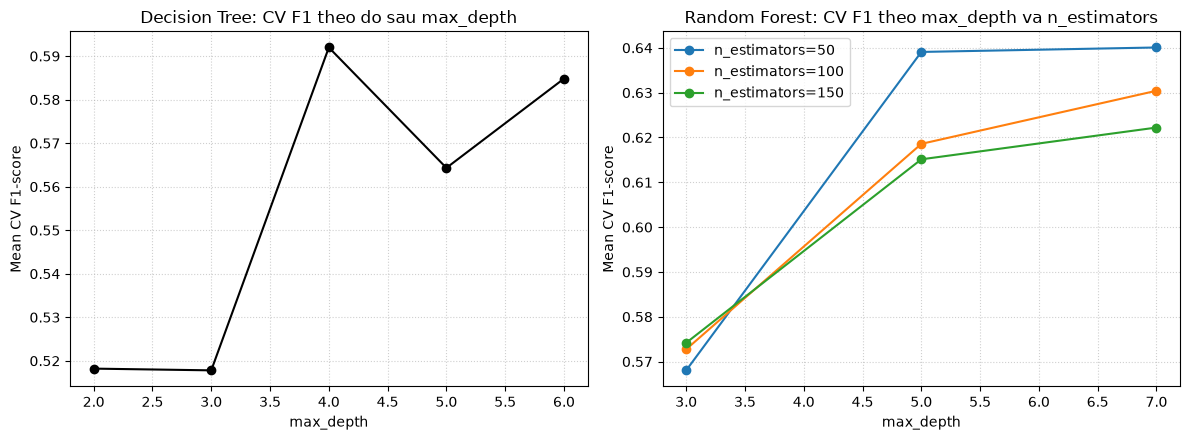

In [3]:
param_dt = {'max_depth': [2, 3, 4, 5, 6], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_dt, cv=5, scoring='f1').fit(X_train, y_train)
best_dt = grid_dt.best_estimator_
print(f"DT Best params: {grid_dt.best_params_}, CV F1: {grid_dt.best_score_:.4f}")

param_rf = {'n_estimators': [50, 100, 150], 'max_depth': [3, 5, 7], 'min_samples_split': [2, 5], 'min_samples_leaf': [2, 4], 'max_features': ['sqrt']}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_rf, cv=5, scoring='f1').fit(X_train, y_train)
best_rf = grid_rf.best_estimator_
print(f"RF Best params: {grid_rf.best_params_}, CV F1: {grid_rf.best_score_:.4f}")

# Bieu do danh gia qua trinh tuning
cv_dt = pd.DataFrame(grid_dt.cv_results_)
dt_depth_scores = cv_dt.groupby('param_max_depth')['mean_test_score'].max()
cv_rf = pd.DataFrame(grid_rf.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(dt_depth_scores.index, dt_depth_scores.values, '-o', color='black')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('Mean CV F1-score')
axes[0].set_title('Decision Tree: CV F1 theo do sau max_depth')
axes[0].grid(True, linestyle=':', alpha=0.6)

for nest in [50, 100, 150]:
    sub = cv_rf[cv_rf['param_n_estimators'] == nest]
    sub_grouped = sub.groupby('param_max_depth')['mean_test_score'].max()
    axes[1].plot(sub_grouped.index, sub_grouped.values, '-o', label=f'n_estimators={nest}')
axes[1].set_xlabel('max_depth')
axes[1].set_ylabel('Mean CV F1-score')
axes[1].set_title('Random Forest: CV F1 theo max_depth va n_estimators')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


### 4. Đánh giá kiểm tra đầy đủ và vẽ ma trận nhầm lẫn


=== Ket qua Decision Tree Tuned ===
Accuracy : 0.7857
Precision: 0.6981
Recall   : 0.6852
F1-score : 0.6916
ROC-AUC  : 0.7887

Classification Report Decision Tree:
               precision    recall  f1-score   support

           0       0.83      0.84      0.84       100
           1       0.70      0.69      0.69        54

    accuracy                           0.79       154
   macro avg       0.76      0.76      0.76       154
weighted avg       0.78      0.79      0.79       154

=== Ket qua Random Forest Tuned ===
Accuracy : 0.7532
Precision: 0.6905
Recall   : 0.537
F1-score : 0.6042
ROC-AUC  : 0.8119

Classification Report Random Forest:
               precision    recall  f1-score   support

           0       0.78      0.87      0.82       100
           1       0.69      0.54      0.60        54

    accuracy                           0.75       154
   macro avg       0.73      0.70      0.71       154
weighted avg       0.75      0.75      0.74       154



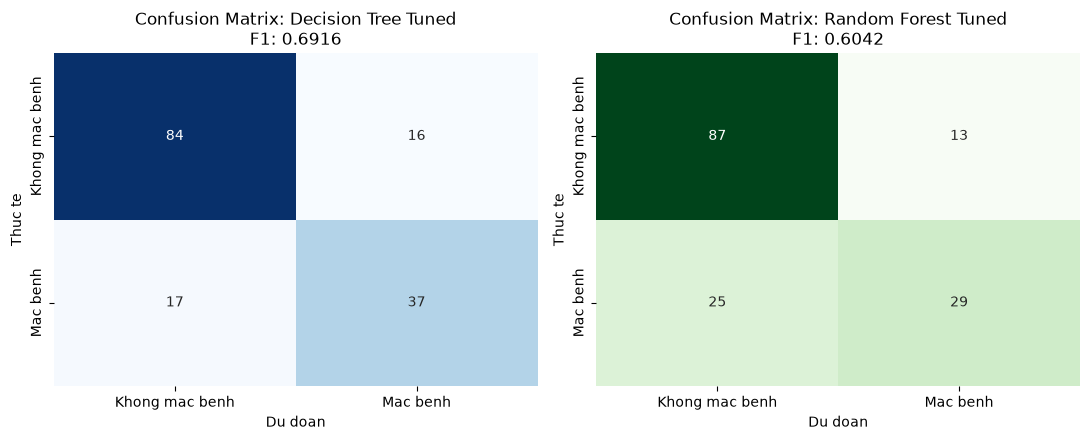

In [4]:
y_pred_dt = best_dt.predict(X_test)
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]

y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

print("=== Ket qua Decision Tree Tuned ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt), 4))
print("Recall   :", round(recall_score(y_test, y_pred_dt), 4))
print("F1-score :", round(f1_score(y_test, y_pred_dt), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_dt), 4))
print("\nClassification Report Decision Tree:\n", classification_report(y_test, y_pred_dt))

print("=== Ket qua Random Forest Tuned ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1-score :", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))
print("\nClassification Report Random Forest:\n", classification_report(y_test, y_pred_rf))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Khong mac benh', 'Mac benh'], yticklabels=['Khong mac benh', 'Mac benh'])
axes[0].set_title(f"Confusion Matrix: Decision Tree Tuned\nF1: {f1_score(y_test, y_pred_dt):.4f}")
axes[0].set_xlabel('Du doan')
axes[0].set_ylabel('Thuc te')

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Khong mac benh', 'Mac benh'], yticklabels=['Khong mac benh', 'Mac benh'])
axes[1].set_title(f"Confusion Matrix: Random Forest Tuned\nF1: {f1_score(y_test, y_pred_rf):.4f}")
axes[1].set_xlabel('Du doan')
axes[1].set_ylabel('Thuc te')

plt.tight_layout()
plt.show()


### 5. Trực quan hóa Cây quyết định tối ưu và Feature Importance


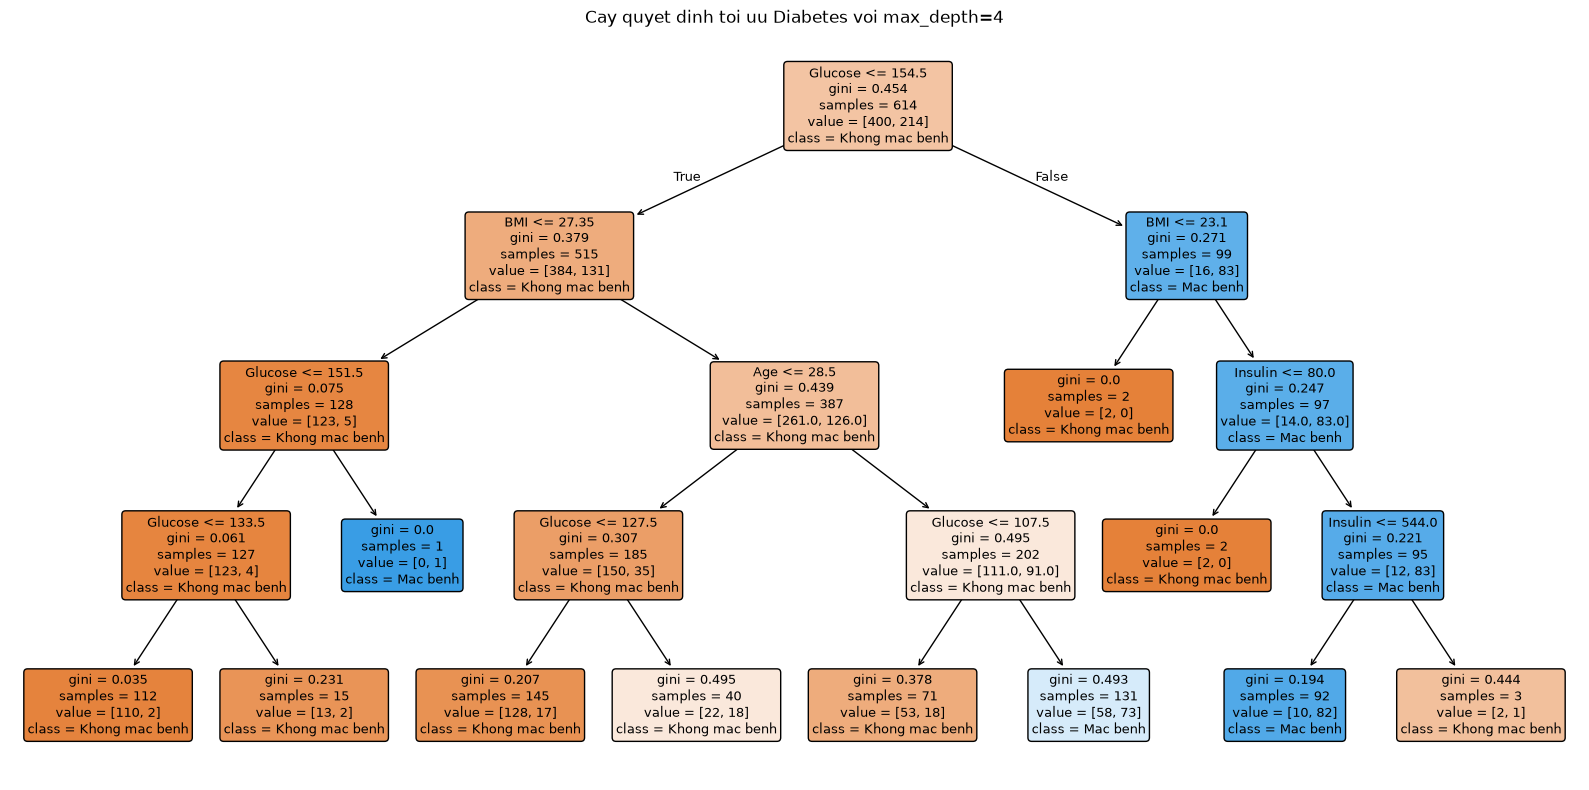

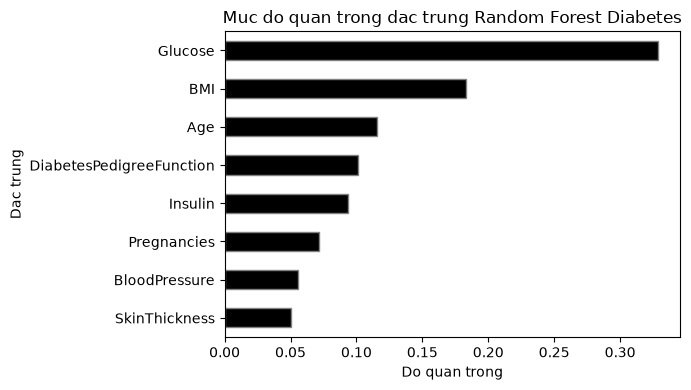

In [5]:
plt.figure(figsize=(16, 8), dpi=400)
plot_tree(best_dt, feature_names=features, class_names=['Khong mac benh', 'Mac benh'], filled=True, rounded=True, fontsize=9)
plt.title(f"Cay quyet dinh toi uu Diabetes voi max_depth={best_dt.max_depth}")
plt.tight_layout()
plt.show()

fi = pd.Series(best_rf.feature_importances_, index=features).sort_values(ascending=True)
plt.figure(figsize=(7, 4))
fi.plot(kind='barh', color='black', edgecolor='gray')
plt.xlabel('Do quan trong')
plt.ylabel('Dac trung')
plt.title('Muc do quan trong dac trung Random Forest Diabetes')
plt.tight_layout()
plt.show()


### 6. Bảng tổng hợp so sánh trực diện và nhận xét về hiện tượng quá khớp
So sánh hiệu năng giữa Baseline và Tuned cho Decision Tree và Random Forest:


In [6]:
summary_di = pd.DataFrame([
    {
        'Model': 'DT Baseline',
        'Train Acc': round(dt_base.score(X_train, y_train), 4),
        'Test Acc': round(dt_base.score(X_test, y_test), 4),
        'Precision': round(precision_score(y_test, dt_base.predict(X_test)), 4),
        'Recall': round(recall_score(y_test, dt_base.predict(X_test)), 4),
        'F1-Score': round(f1_score(y_test, dt_base.predict(X_test)), 4),
        'ROC-AUC': round(roc_auc_score(y_test, dt_base.predict_proba(X_test)[:, 1]), 4)
    },
    {
        'Model': 'DT Tuned',
        'Train Acc': round(best_dt.score(X_train, y_train), 4),
        'Test Acc': round(best_dt.score(X_test, y_test), 4),
        'Precision': round(precision_score(y_test, y_pred_dt), 4),
        'Recall': round(recall_score(y_test, y_pred_dt), 4),
        'F1-Score': round(f1_score(y_test, y_pred_dt), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob_dt), 4)
    },
    {
        'Model': 'RF Baseline',
        'Train Acc': round(rf_base.score(X_train, y_train), 4),
        'Test Acc': round(rf_base.score(X_test, y_test), 4),
        'Precision': round(precision_score(y_test, rf_base.predict(X_test)), 4),
        'Recall': round(recall_score(y_test, rf_base.predict(X_test)), 4),
        'F1-Score': round(f1_score(y_test, rf_base.predict(X_test)), 4),
        'ROC-AUC': round(roc_auc_score(y_test, rf_base.predict_proba(X_test)[:, 1]), 4)
    },
    {
        'Model': 'RF Tuned',
        'Train Acc': round(best_rf.score(X_train, y_train), 4),
        'Test Acc': round(best_rf.score(X_test, y_test), 4),
        'Precision': round(precision_score(y_test, y_pred_rf), 4),
        'Recall': round(recall_score(y_test, y_pred_rf), 4),
        'F1-Score': round(f1_score(y_test, y_pred_rf), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob_rf), 4)
    }
])
print(summary_di.to_string(index=False))


      Model  Train Acc  Test Acc  Precision  Recall  F1-Score  ROC-AUC
DT Baseline     1.0000    0.6818     0.5532  0.4815    0.5149   0.6357
   DT Tuned     0.7948    0.7857     0.6981  0.6852    0.6916   0.7887
RF Baseline     1.0000    0.7662     0.6957  0.5926    0.6400   0.8210
   RF Tuned     0.8941    0.7532     0.6905  0.5370    0.6042   0.8119


Nhận xét cụ thể về hiện tượng quá khớp:
1. Decision Tree Baseline không khống chế độ sâu đạt độ chính xác huấn luyện tuyệt đối 100%, nhưng trên tập kiểm tra chỉ đạt 68.18% và F1-score đạt 0.5149. Chênh lệch 31.82% phản ánh hiện tượng quá khớp nặng khi cây cố gắng phân tách từng điểm nhiễu.
2. Sau khi dùng GridSearchCV khống chế max_depth=4, độ chính xác huấn luyện giảm về 79.48% nhưng độ chính xác kiểm tra tăng lên 78.57% và F1-score tăng lên 0.6916, chứng tỏ kiểm soát độ sâu giúp mô hình có khả năng tổng quát hóa cao.
3. Random Forest duy trì ROC-AUC kiểm tra ổn định ở mức 0.8041 đến 0.8192, thể hiện ưu thế của phương pháp kết hợp rừng cây trong việc chống quá khớp.
